# CommitBench filtering — Python only (local CSV files)

This notebook reads the CommitBench CSV files that you manually downloaded into `data/raw/`.
It does **not** download the dataset from Hugging Face.

## Expected input files
- `data/raw/train.csv`
- `data/raw/val.csv` (or `validation.csv`)
- `data/raw/test.csv`

The notebook also checks the exact filenames and prints what it finds. It expects each CSV to contain a diff column and a commit-message column (usually `diff` and `message`).

## Outputs
- `data/processed/train.jsonl`
- `data/processed/validation.jsonl`
- `data/processed/test.jsonl`
- `data/processed/plots/original_dataset_overview.png`
- `data/processed/plots/cleaned_dataset_overview.png`
- `commitbench-python-filtered.zip`

Each JSONL record contains `diff` and `message`.

## Filtering steps
- Keeps Python-only changes based on changed-file extensions, with language metadata as a fallback.
- Keeps Conventional Commit messages and removes low-content messages.
- Removes generated/lock files, truncates long diffs, and limits files per diff.
- Deduplicates within each split and removes placeholder tokens from labels.
- Does not cap commit types by default; training keeps its natural class distribution.
- Validation/test are not resampled or capped, preserving their evaluation distributions.



Set `LIMIT_PER_SPLIT = 2000` in the configuration cell for a small test run. Set it to `None` to process every row. The limit counts **input rows scanned per split**, so it also speeds up the original-data graphs.


In [1]:
# Install dependencies into the active notebook kernel if needed.
# This uses local CSVs; it does not download CommitBench itself.
%pip install -q datasets tqdm matplotlib


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import hashlib
import json
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
from datasets import load_dataset
from tqdm.auto import tqdm


c:\Users\ASUSD\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# ---------------------------------------------------------------------------
# Configuration — local Kiro / VS Code
# ---------------------------------------------------------------------------

# Preferred path from your project. If the notebook is moved, the relative
# fallback is checked as well.
PROJECT_DIR = Path(r"C:\Users\ASUSD\Desktop\Programing\seniorProject\OffHand")
CANDIDATE_RAW_DIRS = [PROJECT_DIR / "data" / "raw", Path.cwd() / "data" / "raw"]
RAW_DIR = next((p for p in CANDIDATE_RAW_DIRS if p.is_dir()), CANDIDATE_RAW_DIRS[0])

# Output paths are relative to the project folder when it exists.
OUTPUT_ROOT = PROJECT_DIR if PROJECT_DIR.is_dir() else Path.cwd()
OUT_DIR = OUTPUT_ROOT / "data" / "processed"
PLOT_DIR = OUT_DIR / "plots"

# Set to e.g. 2_000 for a quick test; use None for all input rows.
# This limit applies to rows SCANNED, not rows successfully kept.
LIMIT_PER_SPLIT = None

TARGET_LANGUAGE = "python"
# Do not cap only the training split: preserve its natural class distribution.
# Validation/test remain untouched for an honest evaluation.
MAX_PER_TYPE = {}
FIGURE_DPI = 140

print(f"Project/output root: {OUTPUT_ROOT.resolve()}")
print(f"Raw data directory:  {RAW_DIR.resolve()}")
print(f"Output directory:    {OUT_DIR.resolve()}")
print(f"Row limit per split: {LIMIT_PER_SPLIT}")


Project/output root: C:\Users\ASUSD\Desktop\Programing\seniorProject\OffHand
Raw data directory:  C:\Users\ASUSD\Desktop\Programing\seniorProject\OffHand\data\raw
Output directory:    C:\Users\ASUSD\Desktop\Programing\seniorProject\OffHand\data\processed
Row limit per split: None


In [4]:
# ---------------------------------------------------------------------------
# Filtering helpers (mirrors src/commit_model/diff_utils.py — kept inline so
# the notebook is self-contained and runs on Kaggle / Colab without the package)
# ---------------------------------------------------------------------------

CONVENTIONAL_PREFIX = re.compile(
    r"^(feat|fix|refactor|chore|docs|test|perf|style|build|ci)(\([\w./-]+\))?!?:\s+\S"
)

# Regex that matches the type prefix only (used for per-type counting)
TYPE_RE = re.compile(r"^(\w+)(\(.+?\))?!?:")

LOW_CONTENT_STOPLIST = {
    "fix", "wip", "update", "updates", "minor", "minor changes", "misc",
    "cleanup", "small fix", "typo", "changes", "stuff", "test", "tmp",
    "asdf", "oops", "fixup",
}

GENERATED_FILE_PATTERNS = [
    re.compile(p) for p in [
        r"package-lock\.json$", r"yarn\.lock$", r"pnpm-lock\.yaml$",
        r"Cargo\.lock$", r"Gemfile\.lock$", r"poetry\.lock$", r"uv\.lock$",
        r"\.min\.(js|css)$", r"\.map$", r"(?:^|/)dist/", r"(?:^|/)build/", r"(?:^|/)vendor/",
        r"\.svg$", r"\.snap$",
    ]
]

MAX_DIFF_CHARS = 4000
MAX_FILES_PER_DIFF = 6

# Placeholders injected by CommitBench into anonymised messages.
# Strip them from training data so the model never learns to generate them.
# (At inference time, postprocess.py also strips them — this is the training-side fix.)
_PLACEHOLDER_RE = re.compile(
    r"<(I|URL|EMAIL|HASH)>"
    r"|\(#<I>\)"
    r"|\b[0-9a-f]{7,40}\b"  # bare hex hashes that escaped the <HASH> anonymisation
    r"|https?://\S+"         # bare URLs that escaped the <URL> anonymisation
)


def is_generated_path(path: str) -> bool:
    return any(p.search(path) for p in GENERATED_FILE_PATTERNS)


def message_is_low_content(message: str) -> bool:
    first_line = message.strip().splitlines()[0] if message.strip() else ""
    has_prefix = CONVENTIONAL_PREFIX.match(first_line)
    subject = first_line.split(":", 1)[-1].strip() if has_prefix else first_line
    normalized = subject.lower().strip(" .!")
    return len(normalized) < 8 or normalized in LOW_CONTENT_STOPLIST


def split_diff_by_file(diff: str):
    """Split a unified diff into (path, hunk_text) chunks."""
    chunks = re.split(r"(?=^diff --git )", diff, flags=re.MULTILINE)
    files = []
    for chunk in chunks:
        if not chunk.strip():
            continue
        match = re.search(r"^diff --git a/(\S+) b/(\S+)", chunk)
        path = match.group(2) if match else "unknown"
        files.append((path, chunk))
    return files


def truncate_diff(diff: str):
    """Drop generated/lockfile paths, cap file count, and cap total length."""
    files = split_diff_by_file(diff)
    kept = [(p, c) for p, c in files if not is_generated_path(p)]
    if not kept:
        return None
    kept = kept[:MAX_FILES_PER_DIFF]
    pieces = []
    for path, chunk in kept:
        share = max(MAX_DIFF_CHARS // max(len(kept), 1), 200)
        pieces.append(chunk[:share])
    return "".join(pieces)[:MAX_DIFF_CHARS]


def clean_training_message(message: str) -> str:
    """Strip CommitBench placeholder tokens from a training message.

    Does NOT apply the lowercase-first-word cosmetic from postprocess.py —
    that is inference-time only and should not alter training labels.
    Returns an empty string if nothing meaningful remains after cleaning.
    """
    cleaned = _PLACEHOLDER_RE.sub("", message)
    # Collapse multiple spaces and trim
    cleaned = re.sub(r"[ \t]{2,}", " ", cleaned).strip()
    # Collapse dangling punctuation left behind: 'fix: (#)' -> 'fix:'
    cleaned = re.sub(r":\s*[()#\[\]]+\s*$", "", cleaned).strip()
    return cleaned


def extract_type(message: str):
    """Return the commit type prefix string, or None."""
    m = TYPE_RE.match(message.strip())
    return m.group(1) if m else None


# ---------------------------------------------------------------------------
# Programming-language filtering
# ---------------------------------------------------------------------------

_LANGUAGE_ALIASES = {
    "py": "python",
    "python": "python",
    "js": "javascript",
    "javascript": "javascript",
    "ts": "typescript",
    "typescript": "typescript",
    "java": "java",
    "go": "go",
    "php": "php",
    "rb": "ruby",
    "ruby": "ruby",
    "c++": "cpp",
    "cpp": "cpp",
    "py3": "python",
}


def _normalise_language(value: str) -> str:
    value = str(value).strip().lower()
    return _LANGUAGE_ALIASES.get(value, value)


def _languages_from_metadata(row: dict):
    """Return normalized language metadata, or None when no usable field exists."""
    for key in ("diff_languages", "languages", "language"):
        if key not in row or row[key] is None:
            continue
        value = row[key]
        if isinstance(value, (list, tuple, set)):
            raw_values = list(value)
        else:
            raw_values = re.split(r"[,;|]", str(value))
        languages = {
            _normalise_language(v)
            for v in raw_values
            if str(v).strip() and str(v).strip().lower() not in {"none", "nan", "unknown"}
        }
        if languages:
            return languages
    return None


def _languages_from_diff_paths(diff: str):
    """Infer languages from changed file extensions; unknown extensions are rejected."""
    paths = re.findall(
        r"^diff --git a/(.*?) b/(.*?)$",
        diff,
        flags=re.MULTILINE,
    )
    if not paths:
        return None

    extension_to_language = {".py": "python"}
    languages = set()
    for old_path, new_path in paths:
        path = new_path or old_path
        suffix = Path(path).suffix.lower()
        language = extension_to_language.get(suffix)
        if language is None:
            return {"__non_python_or_unknown__"}
        languages.add(language)
    return languages or None


def is_target_language_example(row: dict, target_language: str = TARGET_LANGUAGE) -> bool:
    """Keep only diffs whose changed-file paths confirm the target language.

    File extensions take priority because the requirement is Python-only changed
    files. Metadata is used only when paths cannot be parsed from the diff.
    """
    diff = row.get("diff") or ""
    languages_from_paths = _languages_from_diff_paths(diff)
    if languages_from_paths is not None:
        return languages_from_paths == {target_language}

    languages_from_metadata = _languages_from_metadata(row)
    return languages_from_metadata == {target_language}


In [5]:
# ---------------------------------------------------------------------------
# Load the manually downloaded local CommitBench CSV files
# ---------------------------------------------------------------------------

if not RAW_DIR.is_dir():
    raise FileNotFoundError(
        f"Raw data directory does not exist: {RAW_DIR}\n"
        "Create data/raw and put the downloaded CommitBench CSV files there."
    )

csv_files = sorted(RAW_DIR.glob("*.csv"))
if not csv_files:
    raise FileNotFoundError(
        f"No .csv files found in {RAW_DIR}. Found files: "
        f"{[p.name for p in RAW_DIR.iterdir()]}"
    )

print("CSV files found:")
for file in csv_files:
    print(f"  {file.name} ({file.stat().st_size / (1024**2):.1f} MiB)")

# Match common filename variants without requiring exact capitalization.
def find_split_file(aliases):
    for file in csv_files:
        stem = file.stem.lower().replace("-", "_").replace(" ", "_")
        if stem in aliases:
            return file
    for file in csv_files:
        stem = file.stem.lower().replace("-", "_").replace(" ", "_")
        if any(alias in stem for alias in aliases):
            return file
    return None

train_file = find_split_file({"train", "training", "train_set"})
val_file = find_split_file({"val", "valid", "validation", "dev", "val_set"})
test_file = find_split_file({"test", "testing", "test_set"})

if train_file is None:
    raise FileNotFoundError(
        "Could not identify the training CSV. Expected a filename like train.csv. "
        f"CSV files found: {[p.name for p in csv_files]}"
    )

# Map local files to canonical Hugging Face split names.
data_files = {"train": str(train_file)}
if val_file is not None:
    data_files["validation"] = str(val_file)
if test_file is not None:
    data_files["test"] = str(test_file)

print("\nLoading local CSV files with Hugging Face Datasets (no network download):")
for split_name, file_path in data_files.items():
    print(f"  {split_name}: {file_path}")

ds = load_dataset("csv", data_files=data_files)

# Normalize common column-name variants to the names expected by the filter.
for split_name in list(ds.keys()):
    columns = list(ds[split_name].column_names)
    lower_to_actual = {column.lower().strip(): column for column in columns}

    diff_candidates = ("diff", "patch", "code_diff", "diff_text", "changes")
    message_candidates = ("message", "commit_message", "commit_msg", "subject", "commitmessage")

    diff_col = next((lower_to_actual[name] for name in diff_candidates if name in lower_to_actual), None)
    message_col = next((lower_to_actual[name] for name in message_candidates if name in lower_to_actual), None)

    if diff_col is None or message_col is None:
        raise ValueError(
            f"Split '{split_name}' has columns {columns}, but the notebook needs a diff/patch column "
            "and a commit-message column. Please inspect the CSV headers and update the aliases."
        )

    rename_map = {}
    if diff_col != "diff":
        rename_map[diff_col] = "diff"
    if message_col != "message":
        rename_map[message_col] = "message"
    if rename_map:
        ds[split_name] = ds[split_name].rename_columns(rename_map)

print("\nLoaded local dataset:")
for split_name, split in ds.items():
    print(f"  {split_name}: {len(split):,} rows; columns={split.column_names}")

print("\nSample training row:")
print({key: (str(value)[:250] + "...") if isinstance(value, str) and len(value) > 250 else value
       for key, value in ds["train"][0].items()})


CSV files found:
  test.csv (214.6 MiB)
  train.csv (1003.1 MiB)
  val.csv (214.7 MiB)

Loading local CSV files with Hugging Face Datasets (no network download):
  train: C:\Users\ASUSD\Desktop\Programing\seniorProject\OffHand\data\raw\train.csv
  validation: C:\Users\ASUSD\Desktop\Programing\seniorProject\OffHand\data\raw\val.csv
  test: C:\Users\ASUSD\Desktop\Programing\seniorProject\OffHand\data\raw\test.csv

Loaded local dataset:
  train: 1,165,213 rows; columns=['hash', 'diff', 'message', 'project', 'split', 'diff_languages']
  validation: 249,689 rows; columns=['hash', 'diff', 'message', 'project', 'split', 'diff_languages']
  test: 249,688 rows; columns=['hash', 'diff', 'message', 'project', 'split', 'diff_languages']

Sample training row:
{'hash': '5559e14bb3c81d5046dac11f21d57e7de28272eb', 'diff': 'diff --git a/pymatgen/phasediagram/analyzer.py b/pymatgen/phasediagram/analyzer.py\nindex <HASH>..<HASH> 100644\n--- a/pymatgen/phasediagram/analyzer.py\n+++ b/pymatgen/phasediagram

In [6]:
# ---------------------------------------------------------------------------
# Preview — head of each loaded split
# ---------------------------------------------------------------------------

import pandas as pd

for split_name, split in ds.items():
    print(f"=== {split_name} — {len(split):,} rows ==={chr(10)}")
    # Convert first 5 rows to a pandas DataFrame for a clean table display
    head_df = pd.DataFrame(split[:5])
    # Truncate long diff/message values so the table is readable
    for col in head_df.columns:
        head_df[col] = head_df[col].astype(str).str.slice(0, 120)
    display(head_df)
    print(f"Columns: {split.column_names}")
    print()

=== train — 1,165,213 rows ===



,hash,diff,message,project,split,diff_languages
0,5559e14bb3c81d5046dac11f21d57e7de28272eb,diff --git a/pymatgen/phasediagram/analyzer.py...,refactoring to use PhaseDiagram.pd_coords,materialsproject_pymatgen,train,py
1,221aab3352ebef9b7f3d215b8adafcb44db1c3ff,diff --git a/lib/core/topologies/replset.js b/...,refactor(replset): reduce server count when de...,mongodb_node-mongodb-native,train,js
2,a6ff929e2293c0b291f07dfaac71d56977f55b89,diff --git a/system/src/Grav/Console/Gpm/Index...,"If there is no repository data, display a nice...",getgrav_grav,train,php
3,c088700e2d4a2f5e509ec9067523f261cd6ccb88,diff --git a/lib/bibreformat.py b/lib/bibrefor...,BibFormat: HDREF processing bug fix\n\n* Fixes...,inveniosoftware_invenio-formatter,train,py
4,244c43c3ecb66a8a8534414bbc7f15b4f049ed22,diff --git a/src/lib/Supra/Controller/Pages/Tw...,Task #<I>: Block titles\nfast-fix implementati...,sitesupra_sitesupra,train,php


Columns: ['hash', 'diff', 'message', 'project', 'split', 'diff_languages']

=== validation — 249,689 rows ===



,hash,diff,message,project,split,diff_languages
0,9d5ab39a05e857e7ada5232d73ca4808ce78a3c4,diff --git a/lib/rudy/routines/helpers/scripth...,Ensure we return to the directory we started i...,solutious_rudy,val,rb
1,29156df21eafff179e7a1854458e3a9b9db50d68,diff --git a/redisson/src/main/java/org/rediss...,Fixed - Redisson cluster cannot recover if Red...,redisson_redisson,val,java
2,a8a933158fbc11aa65aa385a86108e1d77943b72,diff --git a/translate/coroutines.py b/transla...,bug fix when transliteration doesnt exist prin...,jjangsangy_py-translate,val,py
3,4b5dd731f5d39085b78a02fea2c94d229b3f8817,diff --git a/userena/mail.py b/userena/mail.py...,fix issue #<I>\n\nthe issue was fixed in html2...,bread-and-pepper_django-userena,val,py
4,dc5c31fedbb9661562bb4994469567fcd04f39b3,diff --git a/setup.py b/setup.py\nindex <HASH>...,add feature_selection to setup.py,jeongyoonlee_Kaggler,val,py


Columns: ['hash', 'diff', 'message', 'project', 'split', 'diff_languages']

=== test — 249,688 rows ===



,hash,diff,message,project,split,diff_languages
0,713a0a528e7b8ab7348d8e43d3e3aa2e234b20ab,diff --git a/Auth/OpenID/Message.php b/Auth/Op...,[project @ Fix openid.ns value],openid_php-openid,test,php
1,626e13a211c82f833ade88faabcfa104bbf6c7f6,diff --git a/salt/modules/systemd.py b/salt/mo...,fix bug from systems without any legacy init s...,saltstack_salt,test,py
2,b0bcb691ff789314ec525a74ec0a505e57a20a79,diff --git a/pyvex/lifting/util/vex_helper.py ...,feature: add support for `Iop_Sar<width>` arit...,angr_pyvex,test,py
3,fcc16e4f102d75ef60fa57f0968fa0151dc03632,diff --git a/src/Parse.php b/src/Parse.php\nin...,Created initial validateAlgorithm method in Pa...,RobDWaller_ReallySimpleJWT,test,"php,php"
4,f1a4ce51f75431fd8ae1454a3a90e9d97dde8fda,diff --git a/salt/utils/event.py b/salt/utils/...,Fix for #<I> Reacter process get exited with w...,saltstack_salt,test,py


Columns: ['hash', 'diff', 'message', 'project', 'split', 'diff_languages']



Analyze original test: 100%|██████████| 249688/249688 [00:08<00:00, 29146.55it/s]


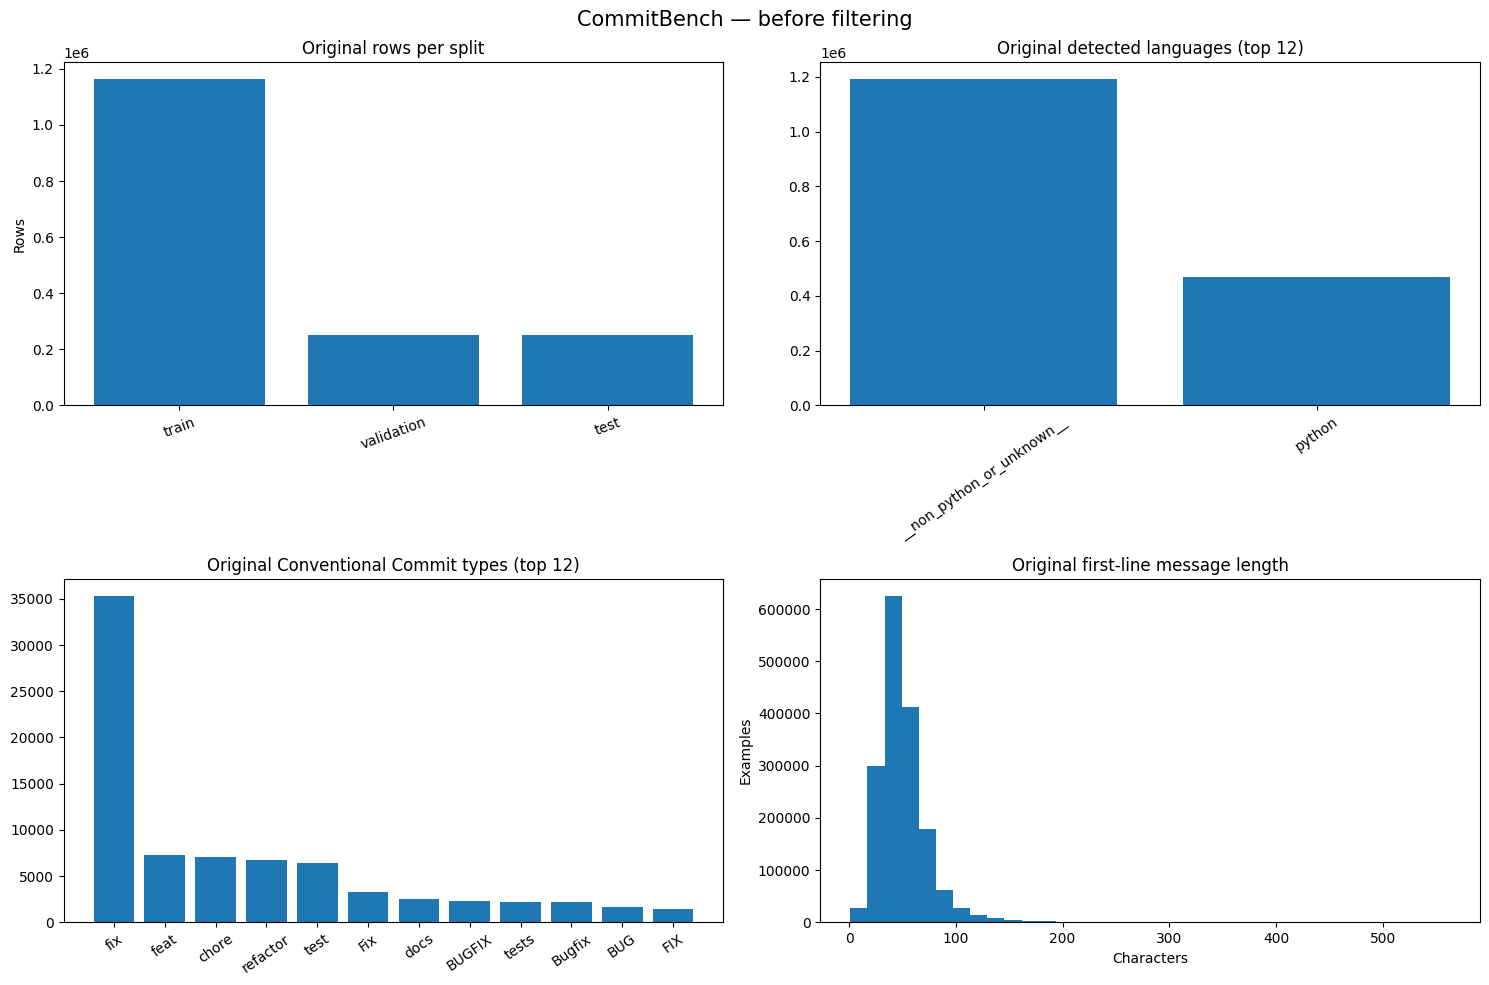

Saved original-data plots to: C:\Users\ASUSD\Desktop\Programing\seniorProject\OffHand\data\processed\plots\original_dataset_overview.png


In [7]:
# ---------------------------------------------------------------------------
# Overview plots — original dataset BEFORE filtering
# ---------------------------------------------------------------------------

def _safe_first_line(message):
    return (message or "").strip().splitlines()[0] if (message or "").strip() else ""


def _language_labels_for_plot(row):
    # Prefer parsed changed-file extensions, then fall back to dataset metadata.
    by_path = _languages_from_diff_paths(row.get("diff") or "")
    langs = by_path if by_path is not None else _languages_from_metadata(row)
    return sorted(langs) if langs else ["unknown"]


original_split_sizes = {}
original_types = Counter()
original_message_lengths = []
original_languages = Counter()

for split_name, split in ds.items():
    rows_to_analyze = split
    if LIMIT_PER_SPLIT is not None:
        rows_to_analyze = split.select(range(min(len(split), LIMIT_PER_SPLIT)))
    original_split_sizes[split_name] = len(rows_to_analyze)
    for row in tqdm(rows_to_analyze, desc=f"Analyze original {split_name}", total=len(rows_to_analyze)):
        message = row.get("message") or ""
        first_line = _safe_first_line(message)
        commit_type = extract_type(first_line)
        if commit_type:
            original_types[commit_type] += 1
        if message.strip():
            original_message_lengths.append(len(first_line))
        for lang in _language_labels_for_plot(row):
            original_languages[lang] += 1

PLOT_DIR.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes[0, 0].bar(list(original_split_sizes.keys()), list(original_split_sizes.values()))
axes[0, 0].set_title("Original rows per split")
axes[0, 0].set_ylabel("Rows")
axes[0, 0].tick_params(axis="x", rotation=20)

top_languages = original_languages.most_common(12)
if top_languages:
    axes[0, 1].bar([x[0] for x in top_languages], [x[1] for x in top_languages])
    axes[0, 1].set_title("Original detected languages (top 12)")
    axes[0, 1].tick_params(axis="x", rotation=35)
else:
    axes[0, 1].set_title("Original detected languages (no metadata/paths found)")

top_types = original_types.most_common(12)
if top_types:
    axes[1, 0].bar([x[0] for x in top_types], [x[1] for x in top_types])
    axes[1, 0].set_title("Original Conventional Commit types (top 12)")
    axes[1, 0].tick_params(axis="x", rotation=35)
else:
    axes[1, 0].set_title("Original commit types (none detected)")

if original_message_lengths:
    axes[1, 1].hist(original_message_lengths, bins=35)
axes[1, 1].set_title("Original first-line message length")
axes[1, 1].set_xlabel("Characters")
axes[1, 1].set_ylabel("Examples")

fig.suptitle("CommitBench — before filtering", fontsize=15)
fig.tight_layout()
original_plot_path = PLOT_DIR / "original_dataset_overview.png"
fig.savefig(original_plot_path, dpi=FIGURE_DPI, bbox_inches="tight")
plt.show()
print(f"Saved original-data plots to: {original_plot_path.resolve()}")


In [8]:
# ---------------------------------------------------------------------------
# Relaxed filtering configuration
# ---------------------------------------------------------------------------

# Type used when nothing else matches. Set to None to reject those rows instead.
INFER_FALLBACK_TYPE = "chore"

# Merge commits rarely describe a single change; set False to keep them.
DROP_MERGE_COMMITS = True

# Thresholds used inside build_example() (previously 20 and 4).
MIN_DIFF_CHARS = 10
MIN_DESCRIPTION_CHARS = 3

# message_is_low_content() is defined elsewhere in your notebook.
# Set to False if "low_content_message" becomes a large rejection reason.
USE_LOW_CONTENT_FILTER = True

# Optional: class caps are disabled by default (MAX_PER_TYPE = {} in the main config).
# Avoid capping training alone unless you intentionally want to alter its distribution.
# If you experiment with caps, report the resulting class distribution and compare it
# against an uncapped baseline. Validation/test are deliberately never capped.

CANONICAL_TYPES = {
    "feat", "fix", "docs", "style", "refactor",
    "perf", "test", "build", "ci", "chore",
}

# Prefix spellings seen in the wild -> canonical type.
TYPE_ALIASES = {
    "feat": "feat", "feature": "feat", "features": "feat", "enh": "feat",
    "enhancement": "feat", "new": "feat", "add": "feat",
    "fix": "fix", "fixes": "fix", "fixed": "fix", "bugfix": "fix",
    "hotfix": "fix", "bug": "fix", "patch": "fix",
    "doc": "docs", "docs": "docs", "documentation": "docs", "readme": "docs",
    "style": "style", "format": "style", "formatting": "style", "lint": "style",
    "refactor": "refactor", "refactoring": "refactor", "cleanup": "refactor",
    "clean": "refactor",
    "perf": "perf", "performance": "perf", "optimization": "perf",
    "optimize": "perf",
    "test": "test", "tests": "test", "testing": "test",
    "build": "build", "deps": "build", "dep": "build", "dependencies": "build",
    "packaging": "build",
    "ci": "ci",
    "chore": "chore", "misc": "chore", "maint": "chore",
    "maintenance": "chore", "release": "chore", "revert": "chore",
}

# Leading verb of a plain-English subject -> type.
VERB_TYPES = {
    "fix": "fix", "fixed": "fix", "fixes": "fix", "fixing": "fix",
    "correct": "fix", "corrected": "fix", "resolve": "fix", "resolved": "fix",
    "repair": "fix", "prevent": "fix", "handle": "fix", "avoid": "fix",
    "add": "feat", "added": "feat", "adds": "feat", "adding": "feat",
    "implement": "feat", "implemented": "feat", "introduce": "feat",
    "support": "feat", "enable": "feat", "allow": "feat", "create": "feat",
    "refactor": "refactor", "refactored": "refactor", "rename": "refactor",
    "renamed": "refactor", "move": "refactor", "moved": "refactor",
    "simplify": "refactor", "cleanup": "refactor", "clean": "refactor",
    "restructure": "refactor", "reorganize": "refactor", "extract": "refactor",
    "split": "refactor", "replace": "refactor", "remove": "refactor",
    "removed": "refactor", "delete": "refactor", "drop": "refactor",
    "document": "docs", "documented": "docs",
    "test": "test", "tested": "test",
    "optimize": "perf", "optimise": "perf", "speed": "perf", "speedup": "perf",
    "format": "style", "reformat": "style", "lint": "style",
    "bump": "build", "upgrade": "build", "pin": "build",
    "update": "chore", "updated": "chore", "updates": "chore",
    "release": "chore", "revert": "chore", "version": "chore",
}

# Verb-derived types that are vague enough that file paths should override them.
GENERIC_VERB_TYPES = {"chore"}

# Keyword anywhere in the subject (checked in this priority order).
KEYWORD_TYPES = [
    (re.compile(r"\b(bug|crash|error|exception|broken|issue|regression)\b", re.I), "fix"),
    (re.compile(r"\b(readme|docstring|documentation|docs?|typo|comment)\b", re.I), "docs"),
    (re.compile(r"\b(tests?|unittest|pytest|coverage)\b", re.I), "test"),
    (re.compile(r"\b(faster|speed|performance|optimi[sz]\w*|cache)\b", re.I), "perf"),
    (re.compile(r"\b(pep8|flake8|black|isort|whitespace|formatting|lint)\b", re.I), "style"),
    (re.compile(r"\b(travis|github actions|workflow|ci)\b", re.I), "ci"),
    (re.compile(r"\b(setup\.py|requirements|dependenc\w*|pyproject|version bump)\b", re.I), "build"),
    (re.compile(r"\b(refactor\w*|cleanup|clean up|rename\w*|simplif\w*)\b", re.I), "refactor"),
    (re.compile(r"\b(new|feature|support for)\b", re.I), "feat"),
]

# Single regex used everywhere for "is this a conventional commit header?"
CONVENTIONAL_HEADER_RE = re.compile(
    r"^(?P<type>[A-Za-z]+)"
    r"(?:\((?P<scope>[^)]*)\))?"
    r"(?P<breaking>!)?"
    r"\s*:\s*(?P<desc>\S.*)$"
)
# "Fix: x", "[fix] - x", "feature - x", "(docs): x"
PREFIX_RE = re.compile(
    r"^\s*[\[\(]?(?P<type>[A-Za-z]+)[\]\)]?"
    r"(?:\((?P<scope>[^)]*)\))?!?"
    r"(?:\s*:\s*|\s+-\s+)(?P<subject>\S.*)$"
)
# "[BUGFIX] x"
BRACKET_RE = re.compile(r"^\s*\[(?P<type>[A-Za-z]+)\]\s*(?P<subject>\S.*)$")
MERGE_RE = re.compile(r"^\s*merge (pull request|branch|remote-tracking)", re.I)
DIFF_PATH_RE = re.compile(r"^(?:diff --git a/(\S+)|\+\+\+ b/(\S+))", re.M)


# ---------------------------------------------------------------------------
# Commit-type normalization helpers (run BEFORE build_example)
# ---------------------------------------------------------------------------

def _changed_paths(diff):
    paths = set()
    for a, b in DIFF_PATH_RE.findall(diff):
        p = a or b
        if p and p != "/dev/null":
            paths.add(p.lower())
    return paths


def _path_category(path):
    name = path.rsplit("/", 1)[-1]
    if (path.startswith(".github/workflows") or path.startswith(".circleci")
            or name in {
                ".travis.yml", ".gitlab-ci.yml", "azure-pipelines.yml",
                "appveyor.yml", "tox.ini", "noxfile.py",
            }):
        return "ci"
    if name in {
        "setup.py", "setup.cfg", "pyproject.toml", "pipfile", "pipfile.lock",
        "poetry.lock", "manifest.in", "makefile", "dockerfile",
    } or (name.startswith("requirements") and name.endswith(".txt")):
        return "build"
    if ("/tests/" in f"/{path}" or "/test/" in f"/{path}"
            or name.startswith("test_") or name.endswith("_test.py")
            or name == "conftest.py"):
        return "test"
    if (path.startswith("docs/") or path.startswith("doc/")
            or name.endswith((".md", ".rst"))):
        return "docs"
    return None


def _file_based_type(diff):
    """Return a type if ALL changed files fall into one category, else None."""
    paths = _changed_paths(diff)
    if not paths:
        return None
    cats = {_path_category(p) for p in paths}
    if len(cats) == 1 and None not in cats:
        return cats.pop()
    return None


def _clean_subject(subject):
    subject = subject.strip().rstrip(".").strip()
    # Lowercase the first letter unless it looks like an acronym ("API", "URL").
    if len(subject) > 1 and subject[0].isupper() and not subject[1].isupper():
        subject = subject[0].lower() + subject[1:]
    return subject


def normalize_commit_message(message, diff):
    """
    Returns (normalized_message, commit_type, label_source)
    or (None, None, rejection_reason).
    """
    lines = message.strip().splitlines()
    first = lines[0].strip()
    body = "\n".join(lines[1:]).strip()

    if DROP_MERGE_COMMITS and MERGE_RE.match(first):
        return None, None, "merge_commit"

    def with_body(header):
        return f"{header}\n\n{body}" if body else header

    def build(ctype, subject, scope=None):
        subject = _clean_subject(subject)
        if not subject:
            return None
        scope_part = f"({scope.strip()})" if scope and scope.strip() else ""
        return with_body(f"{ctype}{scope_part}: {subject}")

    # 1) Already conventional with a known type (any case, optional space).
    #    Only the type casing / spacing is normalized; the subject is untouched.
    m = CONVENTIONAL_HEADER_RE.match(first)
    if m and m.group("type").lower() in CANONICAL_TYPES:
        ctype = m.group("type").lower()
        scope = m.group("scope")
        scope_part = f"({scope.strip()})" if scope and scope.strip() else ""
        bang = "!" if m.group("breaking") else ""
        header = f"{ctype}{scope_part}{bang}: {m.group('desc').strip()}"
        return with_body(header), ctype, "conventional_original"

    # 2) Near-conventional prefixes: "Fix: x", "[BUGFIX] x", "feature - x".
    for regex in (PREFIX_RE, BRACKET_RE):
        m = regex.match(first)
        if m and m.group("type").lower() in TYPE_ALIASES:
            ctype = TYPE_ALIASES[m.group("type").lower()]
            msg = build(ctype, m.group("subject"), m.groupdict().get("scope"))
            if msg:
                return msg, ctype, "salvaged_prefix"

    file_type = _file_based_type(diff)

    # 3) Leading verb: "Fixed crash in parser", "Add retry logic".
    #    Vague verbs ("Update ...") defer to file paths when those are clear.
    words = re.findall(r"[A-Za-z]+", first)
    if words and words[0].lower() in VERB_TYPES:
        ctype = VERB_TYPES[words[0].lower()]
        source = "inferred_from_verb"
        if ctype in GENERIC_VERB_TYPES and file_type:
            ctype, source = file_type, "inferred_from_files"
        msg = build(ctype, first)
        if msg:
            return msg, ctype, source

    # 4) All changed files belong to one category (tests/docs/ci/build).
    if file_type:
        msg = build(file_type, first)
        if msg:
            return msg, file_type, "inferred_from_files"

    # 5) Keyword anywhere in the subject.
    for regex, ctype in KEYWORD_TYPES:
        if regex.search(first):
            msg = build(ctype, first)
            if msg:
                return msg, ctype, "inferred_from_keyword"

    # 6) Fallback.
    if INFER_FALLBACK_TYPE:
        msg = build(INFER_FALLBACK_TYPE, first)
        if msg:
            return msg, INFER_FALLBACK_TYPE, "inferred_fallback"

    return None, None, "type_not_inferable"


# ---------------------------------------------------------------------------
# build_example — central per-row filter with rejection-reason tracking
# ---------------------------------------------------------------------------

def build_example(
    diff: str,
    message: str,
    seen_hashes: set,
    type_counts: dict,
    is_train: bool,
    rejection_counts: Counter,
    require_conventional_format: bool = False,
):
    """Return a filtered example dict, or None while counting its rejection reason.

    Each rejected row increments exactly one reason in rejection_counts.
    """

    def reject(reason):
        rejection_counts[reason] += 1
        return None

    message = (message or "").strip()
    if not message:
        return reject("empty_message")

    first_line = message.splitlines()[0].strip()

    header = CONVENTIONAL_HEADER_RE.match(first_line)
    is_conventional = bool(
        header and header.group("type").lower() in CANONICAL_TYPES
    )

    # Only enforced when explicitly requested (previously always enforced).
    if require_conventional_format and not is_conventional:
        return reject("not_conventional_commit_format")

    if USE_LOW_CONTENT_FILTER and message_is_low_content(message):
        return reject("low_content_message")

    truncated = truncate_diff(diff or "")
    if truncated is None:
        return reject("no_usable_files_after_generated_file_filter")
    if len(truncated.strip()) < MIN_DIFF_CHARS:
        return reject("diff_too_short_after_filtering")

    cleaned_message = (clean_training_message(first_line) or "").strip()
    if not cleaned_message:
        return reject("placeholder_cleaning_removed_message")

    if is_conventional:
        # The message was conventional before cleaning; make sure cleaning
        # didn't break the "type(scope): description" structure.
        cleaned_header = CONVENTIONAL_HEADER_RE.match(cleaned_message)
        if (not cleaned_header
                or cleaned_header.group("type").lower() not in CANONICAL_TYPES):
            return reject("invalid_format_after_cleaning")
        commit_type = cleaned_header.group("type").lower()
        description = cleaned_header.group("desc").strip()
    else:
        # Non-conventional message allowed through (require flag is False).
        commit_type = None
        description = cleaned_message

    if len(description) < MIN_DESCRIPTION_CHARS:
        return reject("description_too_short_after_cleaning")

    h = hashlib.sha256(
        (truncated + "\x00" + cleaned_message).encode("utf-8")
    ).hexdigest()[:16]
    if h in seen_hashes:
        return reject("duplicate_diff_and_message")

    if is_train and commit_type and commit_type in MAX_PER_TYPE:
        if type_counts.get(commit_type, 0) >= MAX_PER_TYPE[commit_type]:
            return reject(f"class_cap_reached_{commit_type}")

    # Only record the hash / count for rows that are actually kept.
    seen_hashes.add(h)
    if commit_type:
        type_counts[commit_type] = type_counts.get(commit_type, 0) + 1

    return {"diff": truncated, "message": cleaned_message}


# ---------------------------------------------------------------------------
# Filter & write Python-only examples — relaxed commit-message filtering
# ---------------------------------------------------------------------------

OUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_SPLIT_NAMES = {
    "train": "train",
    "val": "validation",
    "validation": "validation",
    "test": "test",
}

for split_name in ds.keys():
    if split_name not in OUTPUT_SPLIT_NAMES:
        print(f"Skipping unexpected split '{split_name}'.")
        continue

    split = ds[split_name]
    if LIMIT_PER_SPLIT is not None:
        split = split.select(range(min(len(split), LIMIT_PER_SPLIT)))

    output_name = OUTPUT_SPLIT_NAMES[split_name]
    out_path = OUT_DIR / f"{output_name}.jsonl"
    is_train = split_name == "train"

    seen_hashes = set()
    type_counts = Counter()
    rejection_counts = Counter()
    label_sources = Counter()          # how each KEPT example got its type

    kept = 0
    seen = 0
    python_rows = 0
    language_removed = 0
    placeholder_cleaned = 0

    with out_path.open("w", encoding="utf-8") as f:
        for row in tqdm(
            split,
            desc=f"{split_name} -> {output_name}",
            total=len(split),
        ):
            seen += 1

            # Stage 1: Keep only Python examples.
            if not is_target_language_example(row, TARGET_LANGUAGE):
                language_removed += 1
                continue

            python_rows += 1

            diff = row.get("diff") or ""
            message = (row.get("message") or "").strip()

            if not diff.strip():
                rejection_counts["empty_diff"] += 1
                continue

            if not message:
                rejection_counts["empty_message"] += 1
                continue

            # Record whether the ORIGINAL message contains a placeholder.
            has_placeholder = bool(
                re.search(r"<(I|URL|EMAIL|HASH)>", message)
            )

            # Stage 2: Convert to Conventional Commit form instead of rejecting.
            normalized, _ctype, source = normalize_commit_message(message, diff)
            if normalized is None:
                rejection_counts[source] += 1
                continue

            # Stage 3: Remaining checks (generated files, dedup, caps, cleaning).
            example = build_example(
                diff=diff,
                message=normalized,
                seen_hashes=seen_hashes,
                type_counts=type_counts,
                is_train=is_train,
                rejection_counts=rejection_counts,
                require_conventional_format=False,
            )

            if example is None:
                continue

            if has_placeholder:
                placeholder_cleaned += 1

            label_sources[source] += 1
            f.write(json.dumps(example, ensure_ascii=False) + "\n")
            kept += 1

    rejected_after_language = sum(rejection_counts.values())
    accounted_for = kept + rejected_after_language

    print(
        f"\n{split_name}: kept {kept:,} examples from {seen:,} rows "
        f"({kept / max(seen, 1):.1%}) -> {out_path}"
    )
    print(f"  Python-only rows: {python_rows:,}")
    print(f"  Removed by language filter: {language_removed:,}")
    print(
        f"  Python-only rows rejected by other checks: "
        f"{rejected_after_language:,}"
    )
    print(
        f"  Reconciliation: kept + rejected = {accounted_for:,} "
        f"(Python-only rows = {python_rows:,})"
    )

    if accounted_for != python_rows:
        print(
            "  WARNING: counts do not reconcile; "
            "inspect the filtering loop."
        )

    print(
        "  Placeholder-containing messages included after cleaning: "
        f"{placeholder_cleaned:,}"
    )

    print("  How kept examples got their commit type:")
    if label_sources:
        for src, n in label_sources.most_common():
            print(f"    {src:<28} {n:>9,} ({n / max(kept, 1):.1%} of kept)")
    else:
        print("    None")

    print(
        "  Rejection reasons "
        "(counts are mutually exclusive; each rejected Python row is counted once):"
    )

    if rejection_counts:
        for reason, count in rejection_counts.most_common():
            print(
                f"    {reason:<48} {count:>9,} "
                f"({count / max(python_rows, 1):.1%} of Python-only rows)"
            )
    else:
        print("    None")

    if is_train and MAX_PER_TYPE:
        print(f"  Class cap configuration (train only): {MAX_PER_TYPE}")

    print("  Kept examples by commit type:")
    for t, n in sorted(type_counts.items(), key=lambda x: -x[1]):
        pct = n / max(kept, 1)
        capped = is_train and t in MAX_PER_TYPE and n >= MAX_PER_TYPE[t]
        cap_note = f" [CAP REACHED: {MAX_PER_TYPE[t]}]" if capped else ""
        print(f"    {t:<12} {n:>6} ({pct:.1%}){cap_note}")

print("\nFiltering complete. Expected outputs:")
for name in ("train.jsonl", "validation.jsonl", "test.jsonl"):
    print(f"  {OUT_DIR / name}")

train -> train: 100%|██████████| 1165213/1165213 [01:05<00:00, 17682.86it/s]



train: kept 328,203 examples from 1,165,213 rows (28.2%) -> C:\Users\ASUSD\Desktop\Programing\seniorProject\OffHand\data\processed\train.jsonl
  Python-only rows: 329,920
  Removed by language filter: 835,293
  Python-only rows rejected by other checks: 1,717
  Reconciliation: kept + rejected = 329,920 (Python-only rows = 329,920)
  Placeholder-containing messages included after cleaning: 83,494
  How kept examples got their commit type:
    inferred_from_verb             132,961 (40.5% of kept)
    inferred_fallback              115,573 (35.2% of kept)
    inferred_from_files             37,641 (11.5% of kept)
    inferred_from_keyword           26,638 (8.1% of kept)
    salvaged_prefix                  7,778 (2.4% of kept)
    conventional_original            7,612 (2.3% of kept)
  Rejection reasons (counts are mutually exclusive; each rejected Python row is counted once):
    duplicate_diff_and_message                             849 (0.3% of Python-only rows)
    low_content_messa

validation -> validation: 100%|██████████| 249689/249689 [00:14<00:00, 17399.78it/s]



validation: kept 70,464 examples from 249,689 rows (28.2%) -> C:\Users\ASUSD\Desktop\Programing\seniorProject\OffHand\data\processed\validation.jsonl
  Python-only rows: 70,681
  Removed by language filter: 179,008
  Python-only rows rejected by other checks: 217
  Reconciliation: kept + rejected = 70,681 (Python-only rows = 70,681)
  Placeholder-containing messages included after cleaning: 18,058
  How kept examples got their commit type:
    inferred_from_verb              28,566 (40.5% of kept)
    inferred_fallback               24,936 (35.4% of kept)
    inferred_from_files              8,082 (11.5% of kept)
    inferred_from_keyword            5,594 (7.9% of kept)
    salvaged_prefix                  1,692 (2.4% of kept)
    conventional_original            1,594 (2.3% of kept)
  Rejection reasons (counts are mutually exclusive; each rejected Python row is counted once):
    low_content_message                                    113 (0.2% of Python-only rows)
    no_usable_files

test -> test: 100%|██████████| 249688/249688 [00:13<00:00, 17940.05it/s]


test: kept 69,933 examples from 249,688 rows (28.0%) -> C:\Users\ASUSD\Desktop\Programing\seniorProject\OffHand\data\processed\test.jsonl
  Python-only rows: 70,171
  Removed by language filter: 179,517
  Python-only rows rejected by other checks: 238
  Reconciliation: kept + rejected = 70,171 (Python-only rows = 70,171)
  Placeholder-containing messages included after cleaning: 17,740
  How kept examples got their commit type:
    inferred_from_verb              28,179 (40.3% of kept)
    inferred_fallback               24,748 (35.4% of kept)
    inferred_from_files              7,934 (11.3% of kept)
    inferred_from_keyword            5,727 (8.2% of kept)
    conventional_original            1,709 (2.4% of kept)
    salvaged_prefix                  1,636 (2.3% of kept)
  Rejection reasons (counts are mutually exclusive; each rejected Python row is counted once):
    low_content_message                                    113 (0.2% of Python-only rows)
    no_usable_files_after_gener

## Important interpretation note

This relaxed pipeline **rewrites many original commit messages** into Conventional Commit format using heuristics. In particular, `INFER_FALLBACK_TYPE = "chore"` assigns `chore:` when no rule matches. The resulting labels are partly synthetic, not ground-truth labels. Treat this output as a heuristic-normalized/augmented dataset, not as an untouched CommitBench benchmark. For a fair model evaluation, preserve a separate test set with original messages, and never compare predictions only against labels created by these same heuristics.

The training-only `fix` cap has been **disabled** (`MAX_PER_TYPE = {}`). This avoids deliberately reducing the number of `fix` examples in training while leaving validation/test unchanged. The pipeline now preserves the natural per-split label distributions. Do not apply matching caps to validation/test just to make the counts equal: evaluation splits should remain representative of the held-out data.


train: 328,203 cleaned examples
validation: 70,464 cleaned examples
test: 69,933 cleaned examples

Total cleaned examples checked: 468,600
Schema, non-empty fields, placeholder, and detectable language checks passed.

Sample training examples:
  [1] MESSAGE: refactor: refactoring to use PhaseDiagram.pd_coords
      DIFF:    diff --git a/pymatgen/phasediagram/analyzer.py b/pymatgen/phasediagram/analyzer.py
index <HASH>..<HASH> 100644
--- a/pymatgen/phasediagram/analyzer.py
+++ b/pymatgen/phasediagram/a...

  [2] MESSAGE: fix: bibFormat: HDREF processing bug fix
      DIFF:    diff --git a/lib/bibreformat.py b/lib/bibreformat.py
index <HASH>..<HASH> 100644
--- a/lib/bibreformat.py
+++ b/lib/bibreformat.py
@@ -126,7 +126,7 @@ def bibreformat_task(fmt, sql...

  [3] MESSAGE: chore: decorate EcsRunLauncher as experimental
      DIFF:    diff --git a/python_modules/libraries/dagster-aws/dagster_aws/ecs/launcher.py b/python_modules/libraries/dagster-aws/dagster_aws/ecs/launcher.py
index <HASH

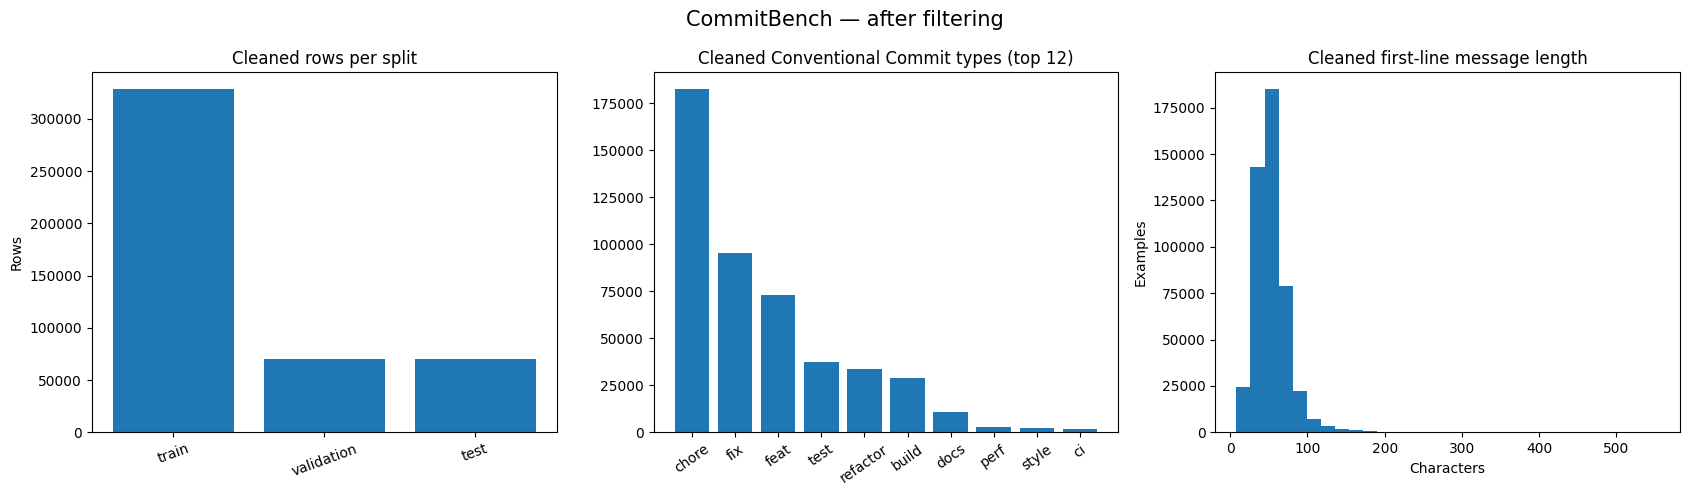

Saved cleaned-data plots to: C:\Users\ASUSD\Desktop\Programing\seniorProject\OffHand\data\processed\plots\cleaned_dataset_overview.png


In [9]:
# ---------------------------------------------------------------------------
# Sanity checks + overview plots — cleaned dataset AFTER filtering
# ---------------------------------------------------------------------------

available_output_files = {
    split_name: OUT_DIR / f"{split_name}.jsonl"
    for split_name in ("train", "validation", "test")
}
cleaned_split_sizes = {}
cleaned_types = Counter()
cleaned_message_lengths = []
total_checked = 0

for split_name, file_path in available_output_files.items():
    if not file_path.exists():
        print(f"Not present (source split may not exist): {file_path}")
        continue

    split_count = 0
    with file_path.open("r", encoding="utf-8") as f:
        for line_number, line in enumerate(f, start=1):
            if not line.strip():
                continue
            row = json.loads(line)
            assert set(row.keys()) == {"diff", "message"}, (
                f"{file_path}:{line_number} has unexpected keys: {row.keys()}"
            )
            assert isinstance(row["diff"], str) and isinstance(row["message"], str)
            assert row["diff"].strip(), f"{file_path}:{line_number} has an empty diff"
            assert row["message"].strip(), f"{file_path}:{line_number} has an empty message"
            for token in ("<I>", "<URL>", "<EMAIL>", "<HASH>"):
                assert token not in row["message"], (
                    f"{file_path}:{line_number} still contains placeholder {token}"
                )

            # Verify the changed paths when the diff format exposes them.
            languages = _languages_from_diff_paths(row["diff"])
            if languages is not None:
                assert languages == {"python"}, (
                    f"{file_path}:{line_number} is not Python-only: {languages}"
                )

            commit_type = extract_type(row["message"])
            if commit_type:
                cleaned_types[commit_type] += 1
            cleaned_message_lengths.append(len(_safe_first_line(row["message"])))
            split_count += 1
            total_checked += 1

    cleaned_split_sizes[split_name] = split_count
    print(f"{split_name}: {split_count:,} cleaned examples")

assert cleaned_split_sizes.get("train", 0) > 0, (
    "train.jsonl is missing or empty. Check the filters and source split names."
)
print(f"\nTotal cleaned examples checked: {total_checked:,}")
print("Schema, non-empty fields, placeholder, and detectable language checks passed.")

# Show a few training examples for a quick manual review.
train_path = OUT_DIR / "train.jsonl"
with train_path.open("r", encoding="utf-8") as f:
    print("\nSample training examples:")
    for i, line in enumerate(f):
        if i >= 3:
            break
        row = json.loads(line)
        print(f"  [{i + 1}] MESSAGE: {row['message']}")
        print(f"      DIFF:    {row['diff'][:180]}...\n")

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
if cleaned_split_sizes:
    axes[0].bar(list(cleaned_split_sizes.keys()), list(cleaned_split_sizes.values()))
axes[0].set_title("Cleaned rows per split")
axes[0].set_ylabel("Rows")
axes[0].tick_params(axis="x", rotation=20)

top_cleaned_types = cleaned_types.most_common(12)
if top_cleaned_types:
    axes[1].bar([x[0] for x in top_cleaned_types], [x[1] for x in top_cleaned_types])
axes[1].set_title("Cleaned Conventional Commit types (top 12)")
axes[1].tick_params(axis="x", rotation=35)

if cleaned_message_lengths:
    axes[2].hist(cleaned_message_lengths, bins=30)
axes[2].set_title("Cleaned first-line message length")
axes[2].set_xlabel("Characters")
axes[2].set_ylabel("Examples")

fig.suptitle("CommitBench — after filtering", fontsize=15)
fig.tight_layout()
cleaned_plot_path = PLOT_DIR / "cleaned_dataset_overview.png"
fig.savefig(cleaned_plot_path, dpi=FIGURE_DPI, bbox_inches="tight")
plt.show()
print(f"Saved cleaned-data plots to: {cleaned_plot_path.resolve()}")
